# Ejercicio explicado: Máquina de Vectores de Soporte (SVM)

Este notebook estudia **Support Vector Machines (SVM)** mediante un problema real de clasificación binaria.

Usaremos el dataset **Breast Cancer Wisconsin** incluido en `scikit-learn`.

## Objetivo

Clasificar tumores como:

- `0 = malignant` → maligno
- `1 = benign` → benigno

El objetivo principal no es únicamente obtener una buena precisión, sino comprender:

1. Qué intenta encontrar una SVM.
2. Qué es el **hiperplano**.
3. Qué significa el **margen**.
4. Qué son los **vectores de soporte**.
5. Por qué debemos escalar las variables.
6. Qué hacen `C` y `gamma`.
7. Para qué sirven los kernels `linear`, `rbf` y `poly`.
8. Cómo elegir hiperparámetros con validación cruzada.
9. Cómo evaluar el modelo mediante matriz de confusión y otras métricas.

---

### Idea central

Una SVM busca una frontera que separe las clases y procura que exista el mayor margen posible entre esa frontera y las observaciones más cercanas.

Esas observaciones cercanas se llaman **vectores de soporte**.

En el caso lineal, la frontera puede escribirse como:

\[
w^Tx+b=0
\]

En más de dos dimensiones ya no hablamos de una simple línea, sino de un **hiperplano**.

## Módulo 1 — Importar librerías

Aquí cargamos las herramientas que utilizaremos durante todo el ejercicio.

- `pandas`: manipulación de datos.
- `numpy`: operaciones numéricas.
- `matplotlib`: gráficas.
- `StandardScaler`: estandarización.
- `SVC`: implementación de Support Vector Classifier.
- Métricas: evaluación de clasificación.
- `GridSearchCV`: búsqueda de hiperparámetros.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

RANDOM_STATE = 42

## Módulo 2 — Cargar el CSV

El archivo contiene:

- 30 variables numéricas.
- `target`: clase que queremos predecir.
- `diagnosis`: nombre legible de la clase.

Las variables describen propiedades calculadas sobre imágenes de núcleos celulares, como radio, textura, perímetro y área.

In [2]:
dataset = pd.read_csv("svm_breast_cancer_dataset.csv")

print("Dimensiones:", dataset.shape)
display(dataset.head())

Dimensiones: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


## Módulo 3 — Revisar estructura y calidad de los datos

Antes de modelar verificamos:

- nombres de columnas;
- tipos de datos;
- valores nulos;
- distribución del target.

Una SVM necesita datos numéricos y no puede trabajar directamente con valores faltantes.

In [3]:
print("Columnas:")
print(dataset.columns.tolist())

print("\nValores nulos:")
print(dataset.isnull().sum().sum())

print("\nDistribución de clases:")
print(dataset["diagnosis"].value_counts())

print("\nProporciones:")
print(dataset["diagnosis"].value_counts(normalize=True).round(3))

Columnas:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target', 'diagnosis']

Valores nulos:
0

Distribución de clases:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64

Proporciones:
diagnosis
benign       0.627
malignant    0.373
Name: proportion, dtype: float64


## Módulo 4 — Separar X e y

Usaremos:

\[
X = \text{variables predictoras}
\]

\[
y = \text{clase que queremos predecir}
\]

Eliminamos `diagnosis` porque es únicamente la versión textual de `target`.

In [4]:
X = dataset.drop(
    columns=[
        "target",
        "diagnosis"
    ]
)

y = dataset["target"]

print("X:", X.shape)
print("y:", y.shape)

X: (569, 30)
y: (569,)


## Módulo 5 — División Train / Test estratificada

Reservamos el 20% para evaluación final.

Usamos `stratify=y` para conservar aproximadamente la misma proporción de malignos y benignos en Train y Test.

`random_state=42` hace que la división sea reproducible.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nClases Train:")
print(y_train.value_counts())

print("\nClases Test:")
print(y_test.value_counts())

Train: (455, 30)
Test: (114, 30)

Clases Train:
target
1    285
0    170
Name: count, dtype: int64

Clases Test:
target
1    72
0    42
Name: count, dtype: int64


## Módulo 6 — ¿Por qué debemos escalar?

SVM utiliza distancias y productos internos.

Si una variable tiene valores de miles y otra tiene valores entre 0 y 1, la primera puede dominar artificialmente la geometría del modelo.

Usaremos:

\[
z=\frac{x-\mu}{\sigma}
\]

Importante:

- `fit_transform()` solamente en Train.
- `transform()` en Test.

Así evitamos **fuga de información**.

In [18]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(
    "Media aproximada Train:",
    np.round(X_train_scaled.mean(axis=0)[:5], 4)
)

print(
    "Desviación aproximada Train:",
    np.round(X_train_scaled.std(axis=0)[:5], 4)
)

Media aproximada Train: [-0.  0. -0. -0.  0.]
Desviación aproximada Train: [1. 1. 1. 1. 1.]


## Módulo 7 — Primer modelo: SVM lineal

`kernel="linear"` intenta separar las clases mediante una frontera lineal.

`C=1.0` controla cuánto penalizamos los errores.

- `C` pequeño → margen más amplio, mayor regularización.
- `C` grande → intenta clasificar correctamente más observaciones, con una frontera más estricta.

Comenzamos con el valor estándar `C=1`.

In [7]:
svm_lineal = SVC(
    kernel="linear",
    C=1.0
)

svm_lineal.fit(
    X_train_scaled,
    y_train
)

y_pred_lineal = svm_lineal.predict(
    X_test_scaled
)

print("Modelo lineal entrenado.")

Modelo lineal entrenado.


## Módulo 8 — Matriz de confusión y métricas del SVM lineal

Para este dataset:

- `0 = malignant`
- `1 = benign`

La matriz nos permite conocer no solo cuántos aciertos hubo, sino **qué tipo de errores** cometió el modelo.

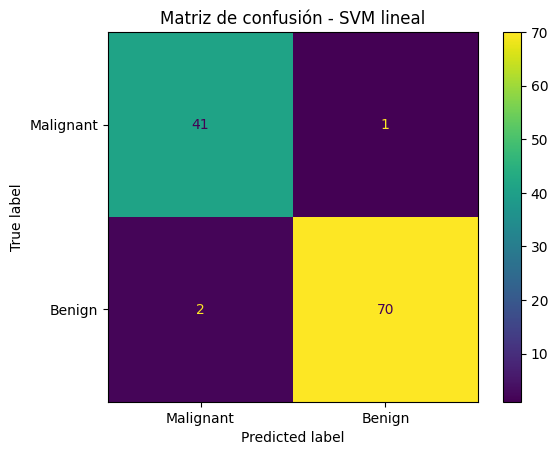

              precision    recall  f1-score   support

   Malignant       0.95      0.98      0.96        42
      Benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [8]:
matriz_lineal = confusion_matrix(
    y_test,
    y_pred_lineal
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_lineal,
    display_labels=[
        "Malignant",
        "Benign"
    ]
)

disp.plot()
plt.title("Matriz de confusión - SVM lineal")
plt.show()

print(
    classification_report(
        y_test,
        y_pred_lineal,
        target_names=[
            "Malignant",
            "Benign"
        ]
    )
)

## Módulo 9 — Vectores de soporte

Los **vectores de soporte** son observaciones especialmente importantes porque se encuentran cerca de la frontera de decisión.

Mover observaciones muy alejadas de la frontera suele tener poco efecto.  
Mover un vector de soporte puede cambiar la frontera.

`n_support_` indica cuántos vectores de soporte utilizó el modelo por clase.

In [9]:
print(
    "Vectores de soporte por clase:",
    svm_lineal.n_support_
)

print(
    "Total de vectores de soporte:",
    svm_lineal.support_vectors_.shape[0]
)

print(
    "Porcentaje de Train que terminó como vector de soporte:",
    round(
        svm_lineal.support_vectors_.shape[0]
        / len(X_train_scaled)
        * 100,
        2
    ),
    "%"
)

Vectores de soporte por clase: [15 17]
Total de vectores de soporte: 32
Porcentaje de Train que terminó como vector de soporte: 7.03 %


## Módulo 10 — Comparar kernels

Una frontera lineal no siempre es suficiente.

Probamos:

- `linear`: separación lineal.
- `rbf`: permite fronteras no lineales y suele ser una excelente opción general.
- `poly`: utiliza relaciones polinomiales.

Para comparar justamente los modelos usamos los mismos datos escalados.

In [10]:
resultados_kernels = []

for kernel in [
    "linear",
    "rbf",
    "poly"
]:

    modelo = SVC(
        kernel=kernel,
        C=1.0,
        gamma="scale"
    )

    modelo.fit(
        X_train_scaled,
        y_train
    )

    pred = modelo.predict(
        X_test_scaled
    )

    resultados_kernels.append({
        "kernel": kernel,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "support_vectors": modelo.support_vectors_.shape[0]
    })

df_kernels = pd.DataFrame(
    resultados_kernels
)

display(
    df_kernels.round(4)
)

,kernel,accuracy,precision,recall,f1,support_vectors
0,linear,0.9737,0.9859,0.9722,0.9790,32
1,rbf,0.9825,0.9861,0.9861,0.9861,97
2,poly,0.9123,0.8780,1.0000,0.9351,145


## Módulo 11 — Efecto del parámetro C

`C` controla el equilibrio entre:

1. mantener un margen amplio;
2. penalizar observaciones mal clasificadas.

Simplificando:

- `C` pequeño → modelo más tolerante a errores.
- `C` grande → intenta ajustarse más a Train.

Un valor demasiado grande puede aumentar el riesgo de sobreajuste.

In [11]:
resultados_c = []

for c in [
    0.01,
    0.1,
    1,
    10,
    100
]:

    modelo = SVC(
        kernel="rbf",
        C=c,
        gamma="scale"
    )

    modelo.fit(
        X_train_scaled,
        y_train
    )

    pred = modelo.predict(
        X_test_scaled
    )

    resultados_c.append({
        "C": c,
        "accuracy": accuracy_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "support_vectors": modelo.support_vectors_.shape[0]
    })

df_c = pd.DataFrame(resultados_c)
display(df_c.round(4))

,C,accuracy,f1,support_vectors
0,0.01,0.6316,0.7742,341
1,0.10,0.9474,0.9589,199
2,1.00,0.9825,0.9861,97
3,10.00,0.9737,0.9790,84
4,100.00,0.9474,0.9571,64


## Módulo 12 — Efecto de gamma en el kernel RBF

`gamma` controla hasta qué distancia influye cada observación.

De forma intuitiva:

- `gamma` pequeño → influencia más amplia, frontera más suave.
- `gamma` grande → influencia muy local, frontera más compleja.

Valores demasiado altos pueden hacer que el modelo memorice demasiado el Train.

In [12]:
resultados_gamma = []

for gamma in [
    0.001,
    0.01,
    0.1,
    1,
    10
]:

    modelo = SVC(
        kernel="rbf",
        C=1.0,
        gamma=gamma
    )

    modelo.fit(
        X_train_scaled,
        y_train
    )

    pred = modelo.predict(
        X_test_scaled
    )

    resultados_gamma.append({
        "gamma": gamma,
        "accuracy": accuracy_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "support_vectors": modelo.support_vectors_.shape[0]
    })

df_gamma = pd.DataFrame(
    resultados_gamma
)

display(
    df_gamma.round(4)
)

,gamma,accuracy,f1,support_vectors
0,0.001,0.9561,0.9664,172
1,0.010,0.9825,0.9861,94
2,0.100,0.9561,0.9645,183
3,1.000,0.6316,0.7742,454
4,10.000,0.6316,0.7742,455


## Módulo 13 — Validación cruzada

Una sola división Train/Test puede favorecer o perjudicar accidentalmente un modelo.

Utilizamos `StratifiedKFold` con 5 folds.

Cada configuración será evaluada cinco veces con diferentes subconjuntos de Train, conservando la proporción de clases.

Para evitar fuga de información dentro de Cross Validation utilizamos un `Pipeline`:

1. `StandardScaler`
2. `SVC`

Así el scaler se ajusta nuevamente dentro de cada fold.

In [13]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

pipeline_rbf = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svm",
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        )
    )
])

scores_cv = cross_val_score(
    pipeline_rbf,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print(
    "F1 por fold:",
    np.round(scores_cv, 4)
)

print(
    "F1 promedio:",
    round(scores_cv.mean(), 4)
)

print(
    "Desviación:",
    round(scores_cv.std(), 4)
)

F1 por fold: [0.9573 0.9821 0.9735 0.9739 0.9913]
F1 promedio: 0.9756
Desviación: 0.0113


## Módulo 14 — GridSearchCV

Ahora dejamos de escoger `C` y `gamma` manualmente.

`GridSearchCV` probará varias combinaciones mediante Cross Validation.

Buscaremos el mejor modelo según **F1-score**, porque combina Precision y Recall.

In [14]:
pipeline_busqueda = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svm",
        SVC()
    )
])

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [
            0.01,
            0.1,
            1,
            10
        ]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [
            0.1,
            1,
            10,
            100
        ],
        "svm__gamma": [
            0.001,
            0.01,
            0.1,
            1
        ]
    }
]

grid = GridSearchCV(
    estimator=pipeline_busqueda,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid.fit(
    X_train,
    y_train
)

print(
    "Mejores parámetros:",
    grid.best_params_
)

print(
    "Mejor F1 de Cross Validation:",
    round(grid.best_score_, 4)
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Mejores parámetros: {'svm__C': 0.1, 'svm__kernel': 'linear'}
Mejor F1 de Cross Validation: 0.981


## Módulo 15 — Evaluación final

Ahora usamos el mejor modelo encontrado por GridSearchCV y lo evaluamos **una sola vez** sobre Test.

Test no participó en la selección de hiperparámetros.

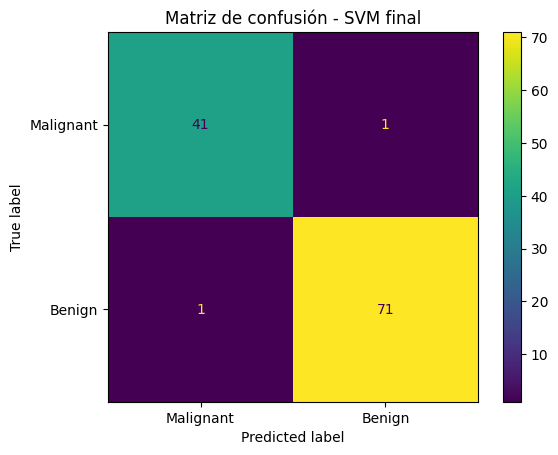

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [15]:
mejor_modelo = grid.best_estimator_

y_pred_final = mejor_modelo.predict(
    X_test
)

matriz_final = confusion_matrix(
    y_test,
    y_pred_final
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_final,
    display_labels=[
        "Malignant",
        "Benign"
    ]
)

disp.plot()
plt.title("Matriz de confusión - SVM final")
plt.show()

print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=[
            "Malignant",
            "Benign"
        ]
    )
)

## Módulo 16 — Visualización didáctica en 2 dimensiones

El modelo real utiliza 30 variables, por lo que su frontera existe en un espacio de muchas dimensiones y no puede dibujarse directamente.

Para comprender visualmente SVM construiremos **otro modelo exclusivamente didáctico** utilizando:

- `mean radius`
- `mean texture`

Este modelo 2D NO reemplaza al modelo final de 30 variables.

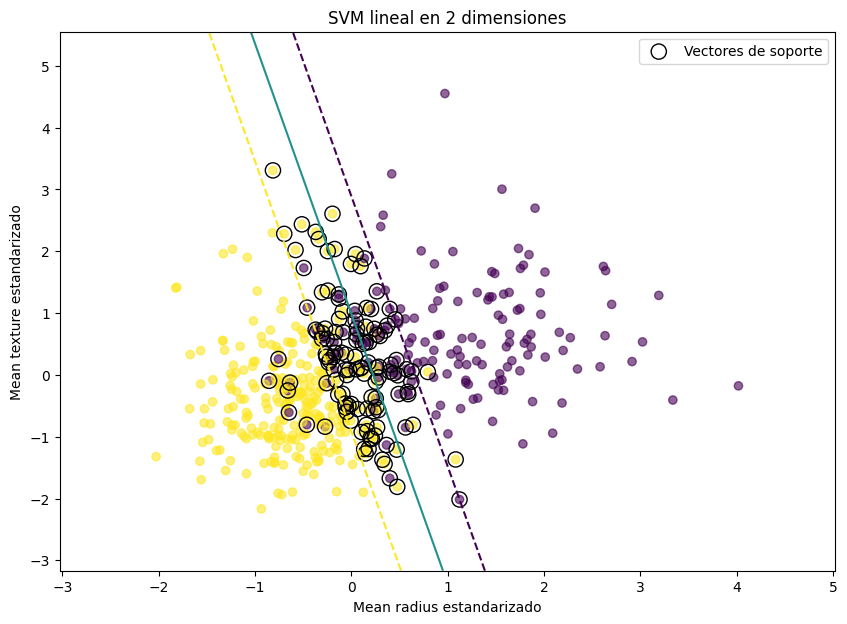

In [16]:
features_2d = [
    "mean radius",
    "mean texture"
]

X_2d = dataset[
    features_2d
].copy()

y_2d = dataset["target"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.20,
    stratify=y_2d,
    random_state=RANDOM_STATE
)

scaler_2d = StandardScaler()

X2_train_scaled = scaler_2d.fit_transform(
    X2_train
)

svm_2d = SVC(
    kernel="linear",
    C=1.0
)

svm_2d.fit(
    X2_train_scaled,
    y2_train
)

x_min = X2_train_scaled[:, 0].min() - 1
x_max = X2_train_scaled[:, 0].max() + 1
y_min = X2_train_scaled[:, 1].min() - 1
y_max = X2_train_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

grid_points = np.c_[
    xx.ravel(),
    yy.ravel()
]

zz = svm_2d.decision_function(
    grid_points
).reshape(xx.shape)

plt.figure(figsize=(10, 7))

plt.contour(
    xx,
    yy,
    zz,
    levels=[-1, 0, 1],
    linestyles=[
        "--",
        "-",
        "--"
    ]
)

plt.scatter(
    X2_train_scaled[:, 0],
    X2_train_scaled[:, 1],
    c=y2_train,
    alpha=0.6
)

plt.scatter(
    svm_2d.support_vectors_[:, 0],
    svm_2d.support_vectors_[:, 1],
    facecolors="none",
    edgecolors="black",
    s=120,
    label="Vectores de soporte"
)

plt.xlabel("Mean radius estandarizado")
plt.ylabel("Mean texture estandarizado")
plt.title("SVM lineal en 2 dimensiones")
plt.legend()
plt.show()

## Módulo 17 — ¿Cómo interpretar la gráfica?

En la gráfica anterior:

- la línea central representa aproximadamente:

\[
w^Tx+b=0
\]

- las líneas discontinuas representan los márgenes;
- los círculos resaltados son los **vectores de soporte**;
- las observaciones alejadas del margen suelen influir menos en la posición exacta de la frontera.

El objetivo conceptual de SVM es encontrar una frontera que consiga una separación útil y, al mismo tiempo, un margen amplio.

## Módulo 18 — Conclusiones

Al finalizar el ejercicio deberías poder explicar:

1. **SVM es un algoritmo supervisado de clasificación.**
2. Busca una frontera de decisión llamada hiperplano.
3. Los vectores de soporte son los puntos más relevantes para determinar esa frontera.
4. El escalado es especialmente importante en SVM.
5. `C` controla la penalización de errores y la regularización.
6. `gamma` controla el alcance de influencia de las observaciones en RBF.
7. Los kernels permiten crear fronteras no lineales.
8. Cross Validation permite comprobar que el desempeño sea estable.
9. GridSearchCV ayuda a seleccionar hiperparámetros sin utilizar el conjunto Test.
10. La matriz de confusión permite analizar qué tipos de errores comete el modelo.

### Preguntas para estudiar

- ¿Por qué no debemos aplicar `fit_transform()` al conjunto Test?
- ¿Qué ocurre cuando `C` es demasiado grande?
- ¿Qué ocurre cuando `gamma` es demasiado grande?
- ¿Por qué un kernel RBF puede separar datos que una SVM lineal no puede?
- ¿Qué diferencia existe entre un vector de soporte y una observación cualquiera?
- ¿Por qué Cross Validation es mejor que escoger hiperparámetros mirando Test?